# Loading indentation maps, processing and PDF-based phase identification

This independent Python workflow loads E/H maps, interpolates and smooths them, plots empirical PDF/CDF distributions, fits a Gaussian mixture, and maps its posterior phase assignments back to the original positions. No MATLAB license is needed.

Install `python -m pip install -r python/requirements.txt` from the repository root, then open this notebook in Jupyter or VS Code. Run cells in order. **Raw measurements are the default statistical sample.** Processed pixels are correlated estimates, not additional independent indents.

The default uses `data_indentation/MTS_example1_25x25_flower.xls`: a **steel matrix containing a carbide flower**, as identified by the dataset owner. The `Results` sheet supplies 625 modulus/hardness pairs at maximum load in GPa. Its Mean, Std. Dev. and % COV rows are excluded by label, not mistaken for indents.

The summary has **no XY coordinates or grid spacing**. The 25-by-25, X-fast serpentine arrangement follows the MATLAB importer; unit grid spacing remains an explicit assumption. Verify scan orientation and physical spacing against acquisition records. CSV rasters, Other-style Excel files and a reproducible synthetic example remain supported.

Gaussian-mixture EM is a statistical deconvolution, not a reproduction of MATLAB's randomized partition-fitting procedure. Components are candidate populations, not automatically physical material phases.

In [1]:
%matplotlib inline
from pathlib import Path
import importlib.metadata as metadata
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from openpyxl import load_workbook
import xlrd
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
if ROOT.name == 'python' and (ROOT.parent / 'data_indentation').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data_indentation').is_dir():
    raise RuntimeError('Start Jupyter from the repository root or its python folder.')

DATA_SOURCE = 'excel'  # 'excel', 'csv', or 'synthetic'
EXCEL_PATH = ROOT / 'data_indentation' / 'MTS_example1_25x25_flower.xls'
SHEET_NAME = 'Results'
GRID_SHAPE = (25, 25)  # (NY, NX); used for the flat Excel table
SERPENTINE = True  # MATLAB MTS convention: reverse every second acquisition row
E_CSV = ROOT / 'data_indentation' / 'modulus.csv'
H_CSV = ROOT / 'data_indentation' / 'hardness.csv'
DX, DY, COORDINATE_UNIT = 1.0, 1.0, 'grid step'
REFINEMENT = 3
SMOOTH_SIGMA = 1.0  # Gaussian sigma in interpolated pixels; zero disables smoothing
FILL_MISSING = False
ANALYSIS_SOURCE = 'raw'  # 'raw' or 'processed'
FIT_PROPERTY = 'H'  # 'H' or 'E'; phase numbering follows this property's means
N_PHASES = 2  # steel matrix and carbide flower; use 3 for the synthetic example
MAX_COMPONENTS = 6
MIN_POSTERIOR = 0.0  # below this confidence, phase 0 denotes an uncertain assignment
SEED = 42
EXPORT = False
EXPORT_DIR = ROOT / 'python' / 'analysis_exports'
print({name: metadata.version(name) for name in ('numpy', 'scipy', 'scikit-learn', 'matplotlib', 'openpyxl', 'xlrd')})

{'numpy': '2.5.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5', 'xlrd': '2.0.2'}


## 1. Load and validate measurements

Excel input supports `.xls` through xlrd and `.xlsx` through openpyxl. Only the chosen summary sheet is loaded, not hundreds of individual load-depth sheets. Supported property headers are `Modulus At Max Load` / `Hardness At Max Load` (MTS) or `AvgModulus` / `AvgHardness` (Other-style input), followed by a `GPa` unit row.

Set `EXCEL_PATH`, `SHEET_NAME`, `GRID_SHAPE` and `SERPENTINE` for your acquisition. A `Test` column must identify each indent once in acquisition order; only the named Mean, Std. Dev. and % COV summary rows are excluded. Missing property cells remain NaN, and measurements are never silently truncated to fit a grid. For `Other_file.xlsx`, choose that path and set `SERPENTINE=False` if its rows already follow raster order.

CSV input uses two **numeric, header-free, same-shaped** rasters: rows along Y, columns along X, values in GPa. Blank/NaN cells stay at their original positions. `GRID_SHAPE` and `SERPENTINE` do not apply to already-arranged CSV rasters. Irregular XY measurements must not be reshaped into a raster without a justified spatial reconstruction.

In [2]:
def read_excel_maps(filename, sheet_name, shape, serpentine=False):
    if len(shape) != 2 or any(isinstance(n, bool) or not isinstance(n, int) or n < 2 for n in shape):
        raise ValueError('GRID_SHAPE must contain two integers >= 2: (NY, NX).')
    extension = Path(filename).suffix.lower()
    if extension == '.xls':
        workbook = xlrd.open_workbook(filename, on_demand=True)
        try:
            sheet = workbook.sheet_by_name(sheet_name)
            rows = [sheet.row_values(row) for row in range(sheet.nrows)]
        finally:
            workbook.release_resources()
    elif extension == '.xlsx':
        workbook = load_workbook(filename, read_only=True, data_only=True)
        try:
            rows = list(workbook[sheet_name].iter_rows(values_only=True))
        finally:
            workbook.close()
    else:
        raise ValueError('Excel input must be .xls or .xlsx; use CSV mode for numeric rasters.')
    if len(rows) < 3:
        raise ValueError('Expected headers, a GPa unit row, and measurements.')
    headers = list(rows[0])
    header_pairs = [('Modulus At Max Load', 'Hardness At Max Load'), ('AvgModulus', 'AvgHardness')]
    matching = [pair for pair in header_pairs if all(headers.count(name) == 1 for name in pair)]
    if len(matching) != 1:
        raise ValueError('Expected one unambiguous MTS max-load or AvgModulus/AvgHardness header pair.')
    columns = [headers.index(name) for name in matching[0]]
    if any(str(rows[1][column]).strip() != 'GPa' for column in columns):
        raise ValueError('Both Excel property columns must explicitly use GPa.')
    measurement_rows = rows[2:]
    if 'Test' in headers:
        test_column = headers.index('Test')
        measurement_rows, test_ids = [], []
        for excel_row, row in enumerate(rows[2:], 3):
            text = str(row[test_column]).strip()
            if text in ('Mean', 'Std. Dev.', '% COV'):
                continue
            try:
                test_id = float(text)
            except ValueError as error:
                raise ValueError(f'Invalid Test identifier in Excel row {excel_row}: {text!r}.') from error
            if not np.isfinite(test_id) or test_id < 1 or test_id != int(test_id):
                raise ValueError(f'Test identifier in row {excel_row} must be a positive integer.')
            test_ids.append(int(test_id))
            measurement_rows.append(row)
        if test_ids != list(range(1, shape[0]*shape[1]+1)):
            raise ValueError('Test identifiers must cover the configured grid exactly once in acquisition order.')
    values = np.asarray([[np.nan if row[column] in (None, '') else row[column] for column in columns]
                         for row in measurement_rows], dtype=float)
    if len(values) != shape[0] * shape[1]:
        raise ValueError(f'{len(values)} measurements do not match GRID_SHAPE={shape}.')
    maps = [values[:, column].reshape(shape).copy() for column in range(2)]
    if serpentine:
        for array in maps:
            array[1::2] = array[1::2, ::-1]
    return maps[0], maps[1]

ground_truth = None
if DATA_SOURCE == 'excel':
    E_raw, H_raw = read_excel_maps(EXCEL_PATH, SHEET_NAME, GRID_SHAPE, SERPENTINE)
    print('Loaded:', EXCEL_PATH.name, '| Verify the assumed grid spacing and scan orientation.')
elif DATA_SOURCE == 'csv':
    E_raw = np.genfromtxt(E_CSV, delimiter=',', ndmin=2)
    H_raw = np.genfromtxt(H_CSV, delimiter=',', ndmin=2)
    print('Loaded CSV rasters:', E_CSV, H_CSV)
elif DATA_SOURCE == 'synthetic':
    rng = np.random.default_rng(SEED)
    yy, xx = np.indices((36, 36))
    ground_truth = 1 + (xx >= 12) + (xx >= 24)
    E_raw = np.array([60.0, 110.0, 170.0])[ground_truth - 1] + rng.normal(0, 5, xx.shape)
    H_raw = np.array([1.5, 3.5, 6.0])[ground_truth - 1] + rng.normal(0, 0.18, xx.shape)
    E_raw[15:18, 15:18] = np.nan
    H_raw[15:18, 15:18] = np.nan
    print('Generated synthetic measurements with three known populations and a missing patch.')
else:
    raise ValueError('Unknown DATA_SOURCE; choose excel, csv, or synthetic.')
if E_raw.ndim != 2 or E_raw.shape != H_raw.shape or min(E_raw.shape) < 2:
    raise ValueError('E and H must be matching 2D rasters with at least two rows and columns.')
if not np.isfinite([DX, DY]).all() or min(DX, DY) <= 0:
    raise ValueError('DX and DY must be positive finite step sizes.')
valid_raw = np.isfinite(E_raw) & np.isfinite(H_raw) & (E_raw > 0) & (H_raw > 0)
if not valid_raw.any():
    raise ValueError('There are no positive finite E/H measurement pairs.')
if not valid_raw.all():
    warnings.warn(f'Excluding {np.count_nonzero(~valid_raw)} missing/nonpositive E/H positions; coordinates are retained.')
E_raw.setflags(write=False)
H_raw.setflags(write=False)
x_raw = np.arange(E_raw.shape[1]) * DX
y_raw = np.arange(E_raw.shape[0]) * DY
print('Raw map shape:', E_raw.shape, '| Valid paired measurements:', np.count_nonzero(valid_raw))

Loaded: MTS_example1_25x25_flower.xls | Verify the assumed grid spacing and scan orientation.
Raw map shape: (25, 25) | Valid paired measurements: 625


## 2. Interpolation and smoothing, without overwriting raw maps

Refinement retains the original sample coordinates and total coordinate span. Bilinear interpolation normalizes contributions from available neighbours; Gaussian smoothing also normalizes by valid-data weights, so missing cells are not treated as zeros. Sigma is measured in **refined-grid pixels**, not original grid steps.

By default, the nearest-cell footprint of missing measurements remains masked during both steps. Setting `FILL_MISSING=True` explicitly permits interpolation/smoothing estimates inside voids where neighbouring support exists; these are not new measurements. Large gaps can remain unsupported and NaN even with filling enabled.

In [3]:
def process_map(values, x, y, refinement, sigma, fill_missing=False):
    if isinstance(refinement, bool) or not isinstance(refinement, int) or refinement < 1:
        raise ValueError('REFINEMENT must be an integer >= 1.')
    if not np.isfinite(sigma) or sigma < 0:
        raise ValueError('SMOOTH_SIGMA must be finite and >= 0.')
    valid = np.isfinite(values)
    if not valid.any():
        raise ValueError('Cannot process a map without finite values.')
    new_x = np.linspace(x[0], x[-1], (len(x)-1)*refinement + 1)
    new_y = np.linspace(y[0], y[-1], (len(y)-1)*refinement + 1)
    yy, xx = np.meshgrid(new_y, new_x, indexing='ij')
    points = np.column_stack((yy.ravel(), xx.ravel()))
    numerator = RegularGridInterpolator((y, x), np.where(valid, values, 0.0))(points)
    support = RegularGridInterpolator((y, x), valid.astype(float))(points)
    interpolated = np.full(len(points), np.nan)
    np.divide(numerator, support, out=interpolated, where=support > 0)
    interpolated = interpolated.reshape(xx.shape)
    footprint = RegularGridInterpolator((y, x), valid.astype(float), method='nearest')(points).reshape(xx.shape) > 0.5
    if not fill_missing:
        interpolated[~footprint] = np.nan
    available = np.isfinite(interpolated)
    smooth_numerator = gaussian_filter(np.where(available, interpolated, 0.0), sigma=sigma, mode='nearest')
    smooth_support = gaussian_filter(available.astype(float), sigma=sigma, mode='nearest')
    smoothed = np.full_like(interpolated, np.nan)
    np.divide(smooth_numerator, smooth_support, out=smoothed, where=smooth_support > 0)
    if not fill_missing:
        smoothed[~footprint] = np.nan
    return interpolated, smoothed, new_x, new_y

E_interpolated, E_processed, x_processed, y_processed = process_map(
    np.where(valid_raw, E_raw, np.nan), x_raw, y_raw, REFINEMENT, SMOOTH_SIGMA, FILL_MISSING)
H_interpolated, H_processed, _, _ = process_map(
    np.where(valid_raw, H_raw, np.nan), x_raw, y_raw, REFINEMENT, SMOOTH_SIGMA, FILL_MISSING)
assert E_processed.shape == H_processed.shape
assert np.array_equal(x_processed[::REFINEMENT], x_raw)
assert np.array_equal(y_processed[::REFINEMENT], y_raw)
np.testing.assert_allclose(E_interpolated[::REFINEMENT, ::REFINEMENT][valid_raw], E_raw[valid_raw])
print('Processed shape:', E_processed.shape, '| Raw arrays remain read-only and unchanged.')

Processed shape: (73, 73) | Raw arrays remain read-only and unchanged.


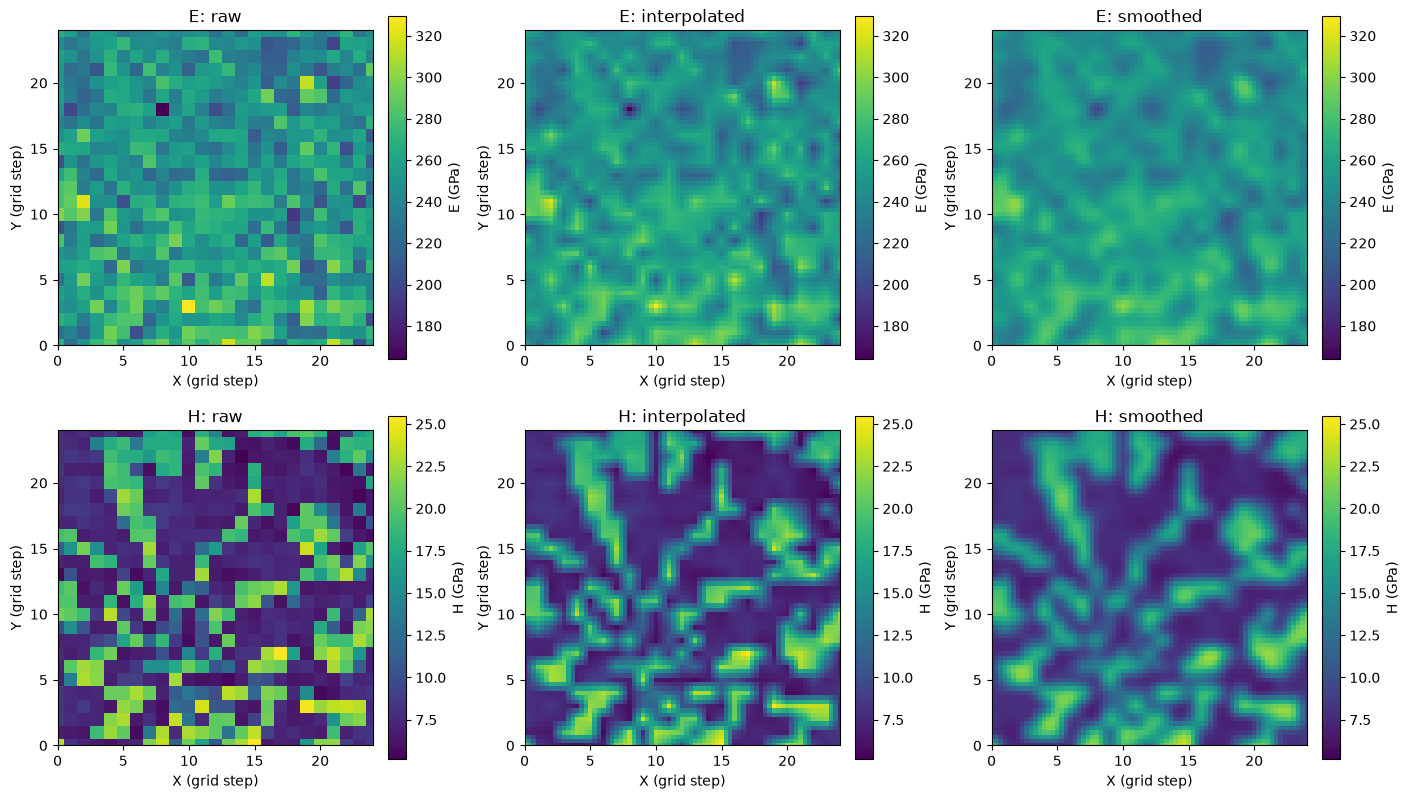

In [4]:
def show_map(ax, values, x, y, title, cmap='viridis', color_norm=None):
    image = ax.pcolormesh(x, y, values, shading='nearest', cmap=cmap, norm=color_norm)
    ax.set(xlim=(x[0], x[-1]), ylim=(y[0], y[-1]), title=title,
           xlabel=f'X ({COORDINATE_UNIT})', ylabel=f'Y ({COORDINATE_UNIT})')
    ax.set_aspect('equal')
    return image

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for row, stages, name in zip(axes, ((E_raw, E_interpolated, E_processed),
                                  (H_raw, H_interpolated, H_processed)), ('E', 'H')):
    limits = plt.Normalize(np.nanmin(stages[0][valid_raw]), np.nanmax(stages[0][valid_raw]))
    for index, (ax, values, stage) in enumerate(zip(row, stages, ('raw', 'interpolated', 'smoothed'))):
        x, y = (x_raw, y_raw) if index == 0 else (x_processed, y_processed)
        image = show_map(ax, np.ma.masked_invalid(values), x, y, f'{name}: {stage}', color_norm=limits)
        fig.colorbar(image, ax=ax, label=f'{name} (GPa)')
plt.show()

## 3. Choose the statistical sample and inspect empirical distributions

Raw mode fits one sample per valid paired indent, irrespective of display refinement. Processed mode fits interpolated/smoothed pixels and changes the distribution and pixel fractions; it must not be used to claim increased statistical independence. Histograms are normalized densities (GPa inverse); empirical CDFs use rank/N. The left/right y-axes deliberately separate density from probability.

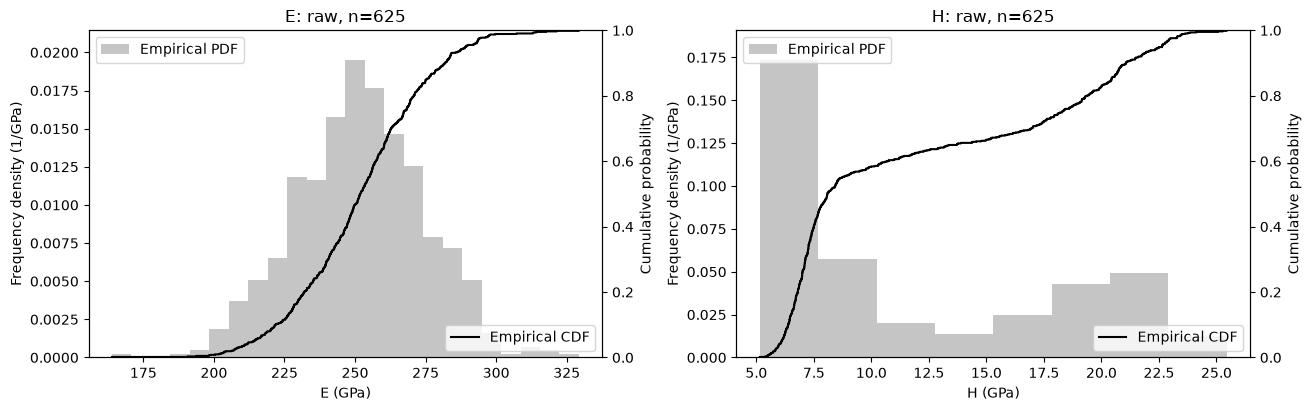

In [5]:
if ANALYSIS_SOURCE == 'raw':
    analysis_E, analysis_H = E_raw, H_raw
elif ANALYSIS_SOURCE == 'processed':
    analysis_E, analysis_H = E_processed, H_processed
    warnings.warn('Fitting processed pixels: these are correlated estimates, not independent indents.')
else:
    raise ValueError('ANALYSIS_SOURCE must be raw or processed.')
analysis_valid = np.isfinite(analysis_E) & np.isfinite(analysis_H) & (analysis_E > 0) & (analysis_H > 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, values, name in zip(axes, (analysis_E, analysis_H), ('E', 'H')):
    sample = values[analysis_valid]
    density, edges, _ = ax.hist(sample, bins='fd', density=True, alpha=0.45, color='gray', label='Empirical PDF')
    cdf_ax = ax.twinx()
    cdf_ax.step(np.sort(sample), np.arange(1, sample.size+1)/sample.size, where='post', color='black', label='Empirical CDF')
    ax.set(xlabel=f'{name} (GPa)', ylabel='Frequency density (1/GPa)',
           ylim=(0, 1.1*np.max(density)), title=f'{name}: {ANALYSIS_SOURCE}, n={sample.size}')
    cdf_ax.set(ylabel='Cumulative probability', ylim=(0, 1))
    ax.legend(loc='upper left')
    cdf_ax.legend(loc='lower right')
plt.show()

## 4. Gaussian-mixture deconvolution and model-size diagnostics

Fit the selected scalar property (`FIT_PROPERTY`). BIC/AIC compare 1 through `MAX_COMPONENTS` Gaussian components on the **same standardized sample**; smaller scores are preferred, but the notebook uses your explicit `N_PHASES`, not an automatic phase-count change. EM uses multiple deterministic initializations and covariance regularization. Non-converged fits raise an error.

Component means and standard deviations are transformed back to GPa. Their weighted PDFs sum to the fitted PDF, and their weighted Gaussian CDFs give its exact analytical integral from minus infinity. Gaussian tails can extend below zero; the reported negative-tail probability is a model limitation, not a physically valid population. BIC and visually good fits are not proof of material-phase identity.

Components       BIC          AIC (standardized sample)
         1      1786.55      1777.67
         2       978.70       956.51
         3       909.79       874.28
         4       925.05       876.24
         5       941.06       878.93
         6       959.74       884.29
BIC suggestion: 3 | Explicit fitted count: 2
Fitted H, source=raw, n=625
1: Steel matrix candidate | mean=7.1406 GPa, SD=0.8148 GPa, mixture weight=0.5660
2: Carbide flower candidate | mean=18.0196 GPa, SD=4.1029 GPa, mixture weight=0.4340
Gaussian probability below zero: 0.000%


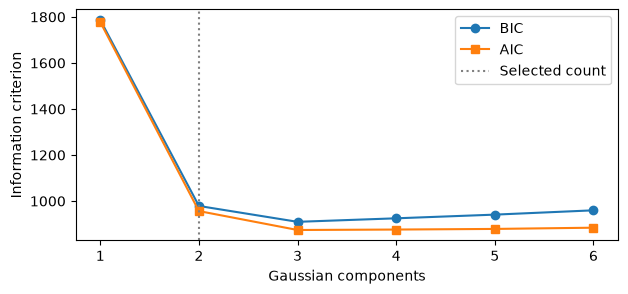

In [6]:
if FIT_PROPERTY not in ('H', 'E'):
    raise ValueError('FIT_PROPERTY must be H or E.')
for name, value in (('N_PHASES', N_PHASES), ('MAX_COMPONENTS', MAX_COMPONENTS)):
    if isinstance(value, bool) or not isinstance(value, int) or value < 1:
        raise ValueError(f'{name} must be a positive integer.')
if N_PHASES > MAX_COMPONENTS:
    raise ValueError('N_PHASES must not exceed MAX_COMPONENTS.')
property_map = analysis_H if FIT_PROPERTY == 'H' else analysis_E
sample = property_map[analysis_valid]
distinct = len(np.unique(sample))
if len(sample) < 3 or distinct < 2 or N_PHASES > distinct:
    raise ValueError('Need at least three samples and enough distinct values for the requested mixture.')
scaler = StandardScaler().fit(sample[:, None])
scaled_sample = scaler.transform(sample[:, None])
models, diagnostics = {}, []
for components in range(1, min(MAX_COMPONENTS, distinct, len(sample))+1):
    candidate = GaussianMixture(n_components=components, covariance_type='full',
                                n_init=5, max_iter=500, reg_covar=1e-6, random_state=SEED)
    candidate.fit(scaled_sample)
    if not candidate.converged_:
        raise RuntimeError(f'{components}-component mixture did not converge; review inputs or iteration settings.')
    models[components] = candidate
    diagnostics.append((components, candidate.bic(scaled_sample), candidate.aic(scaled_sample)))
diagnostics = np.asarray(diagnostics)
model = models[N_PHASES]
phase_order = np.argsort(model.means_[:, 0], kind='stable')
means = scaler.inverse_transform(model.means_)[:, 0][phase_order]
standard_deviations = np.sqrt(model.covariances_[:, 0, 0])[phase_order] * scaler.scale_[0]
weights = model.weights_[phase_order]
phase_names = [f'Phase {phase}' for phase in range(1, N_PHASES+1)]
flower_material_context = (DATA_SOURCE == 'excel' and EXCEL_PATH.name == 'MTS_example1_25x25_flower.xls')
if flower_material_context and FIT_PROPERTY == 'H' and N_PHASES == 2:
    phase_names = ['Steel matrix candidate', 'Carbide flower candidate']
print('Components       BIC          AIC (standardized sample)')
for count, bic, aic in diagnostics:
    print(f'{int(count):10d} {bic:12.2f} {aic:12.2f}')
print('BIC suggestion:', int(diagnostics[np.argmin(diagnostics[:, 1]), 0]), '| Explicit fitted count:', N_PHASES)
print(f'Fitted {FIT_PROPERTY}, source={ANALYSIS_SOURCE}, n={len(sample)}')
for phase, (mean, sd, weight) in enumerate(zip(means, standard_deviations, weights), 1):
    print(f'{phase}: {phase_names[phase-1]} | mean={mean:.4f} GPa, SD={sd:.4f} GPa, mixture weight={weight:.4f}')
negative_tail = float(np.sum(weights * norm.cdf(0, loc=means, scale=standard_deviations)))
print(f'Gaussian probability below zero: {negative_tail:.3%}')
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(diagnostics[:, 0], diagnostics[:, 1], '-o', label='BIC')
ax.plot(diagnostics[:, 0], diagnostics[:, 2], '-s', label='AIC')
ax.axvline(N_PHASES, color='gray', linestyle=':', label='Selected count')
ax.set(xlabel='Gaussian components', ylabel='Information criterion', xticks=diagnostics[:, 0])
ax.legend()
plt.show()

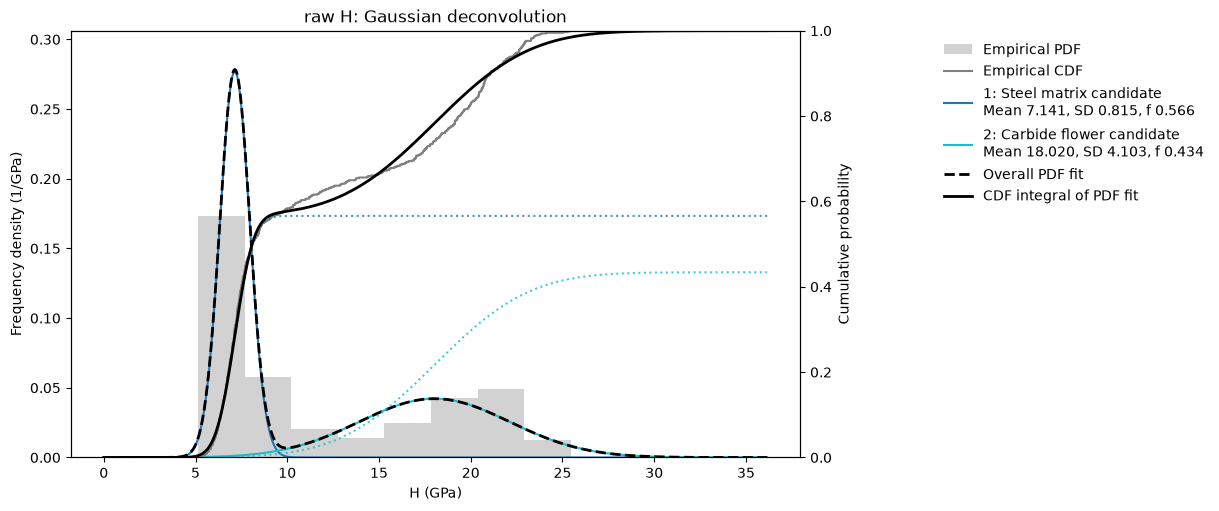

In [7]:
grid = np.linspace(0, max(sample.max(), np.max(means + 4*standard_deviations))*1.05, 800)
component_pdf = norm.pdf(grid[:, None], loc=means, scale=standard_deviations) * weights
component_cdf = norm.cdf(grid[:, None], loc=means, scale=standard_deviations) * weights
total_pdf, total_cdf = component_pdf.sum(axis=1), component_cdf.sum(axis=1)
np.testing.assert_allclose(total_pdf, np.exp(model.score_samples(scaler.transform(grid[:, None]))) / scaler.scale_[0])
assert np.all(np.diff(total_cdf) >= -1e-12) and np.all((total_cdf >= 0) & (total_cdf <= 1+1e-12))
assert np.isclose(weights.sum(), 1)
phase_cmap = plt.get_cmap('tab10', N_PHASES).copy()
phase_cmap.set_bad('lightgray')
phase_norm = BoundaryNorm(np.arange(0.5, N_PHASES+1.5), phase_cmap.N)
fig, pdf_ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
density, edges, bars = pdf_ax.hist(sample, bins='fd', density=True, color='gray', alpha=0.35, label='Empirical PDF')
cdf_ax = pdf_ax.twinx()
empirical_cdf, = cdf_ax.step(np.sort(sample), np.arange(1, len(sample)+1)/len(sample), where='post', color='gray', label='Empirical CDF')
handles, descriptions = [bars, empirical_cdf], ['Empirical PDF', 'Empirical CDF']
for index in range(N_PHASES):
    color = phase_cmap(index)
    phase_line, = pdf_ax.plot(grid, component_pdf[:, index], color=color)
    cdf_ax.plot(grid, component_cdf[:, index], color=color, linestyle=':', alpha=0.8)
    handles.append(phase_line)
    descriptions.append(f'{index+1}: {phase_names[index]}\nMean {means[index]:.3f}, SD {standard_deviations[index]:.3f}, f {weights[index]:.3f}')
pdf_line, = pdf_ax.plot(grid, total_pdf, 'k--', linewidth=2)
cdf_line, = cdf_ax.plot(grid, total_cdf, 'k-', linewidth=2)
pdf_ax.set(xlabel=f'{FIT_PROPERTY} (GPa)', ylabel='Frequency density (1/GPa)',
           ylim=(0, 1.1*max(density.max(), component_pdf.max(), total_pdf.max())),
           title=f'{ANALYSIS_SOURCE} {FIT_PROPERTY}: Gaussian deconvolution')
cdf_ax.set(ylabel='Cumulative probability', ylim=(0, 1))
pdf_ax.legend(handles + [pdf_line, cdf_line], descriptions + ['Overall PDF fit', 'CDF integral of PDF fit'],
              loc='upper left', bbox_to_anchor=(1.18, 1), frameon=False)
plt.show()

## 5. Identify candidate phases using that same deconvolution

The fitted scalar mixture is **not refitted** for phase mapping. At each valid E/H position, evaluate its selected-property posterior and choose the most probable component. Components are numbered by increasing fitted H (or E when selected), and the same numbering is used in both maps and all statistics. Phase 0 denotes invalid measurements or assignments below `MIN_POSTERIOR`.

For this owner's steel/carbide flower dataset, the default two-component H fit associates the lower-hardness population with the **steel matrix candidate** and the higher-hardness population with the **carbide flower candidate**. These names express the supplied material context and an inferred assignment, not a chemical identification from indentation alone. Intermediate indents can mix responses; raise `MIN_POSTERIOR` to leave ambiguous assignments at phase 0. Other inputs, E-only fits and other component counts retain generic phase names. Extra Gaussian components do not automatically mean extra material phases.

Mixture weights are soft distribution fractions. Counts from maximum-posterior assignments are hard fractions and need not equal those weights. Raw-map fractions use all valid raw pairs as their denominator, so uncertain assignments are not silently renormalized away. A scalar-property model cannot separate phases that have indistinguishable selected-property distributions; validate candidates against E/H contrast and independent microstructural evidence.

In [8]:
if not np.isfinite(MIN_POSTERIOR) or not 0 <= MIN_POSTERIOR <= 1:
    raise ValueError('MIN_POSTERIOR must be in [0, 1].')

def assign_phases(modulus, hardness):
    valid = np.isfinite(modulus) & np.isfinite(hardness) & (modulus > 0) & (hardness > 0)
    labels = np.zeros(modulus.shape, dtype=int)
    confidence = np.full(modulus.shape, np.nan)
    posterior = np.full((*modulus.shape, N_PHASES), np.nan)
    if not valid.any():
        raise ValueError('Cannot assign phases without valid E/H pairs.')
    selected = hardness if FIT_PROPERTY == 'H' else modulus
    probabilities = model.predict_proba(scaler.transform(selected[valid, None]))[:, phase_order]
    maximum = probabilities.max(axis=1)
    assigned = probabilities.argmax(axis=1) + 1
    assigned[maximum < MIN_POSTERIOR] = 0
    labels[valid], confidence[valid], posterior[valid] = assigned, maximum, probabilities
    return labels, confidence, posterior

labels_raw, confidence_raw, posterior_raw = assign_phases(E_raw, H_raw)
labels_processed, confidence_processed, posterior_processed = assign_phases(E_processed, H_processed)
assert labels_raw.shape == E_raw.shape and labels_processed.shape == E_processed.shape
assert np.all(labels_raw[~valid_raw] == 0)
np.testing.assert_allclose(posterior_raw[valid_raw].sum(axis=1), 1)
assert np.all(labels_raw[valid_raw & (confidence_raw >= MIN_POSTERIOR)] == posterior_raw[valid_raw & (confidence_raw >= MIN_POSTERIOR)].argmax(axis=1)+1)
if any(not np.any(labels_raw == phase) for phase in range(1, N_PHASES+1)):
    warnings.warn('Some fitted components have no hard-assigned raw measurements; overlapping components need not be distinct phases.')
print('Invalid raw positions:', np.count_nonzero(~valid_raw),
      '| Uncertain raw positions:', np.count_nonzero(valid_raw & (labels_raw == 0)))

Invalid raw positions: 0 | Uncertain raw positions: 0


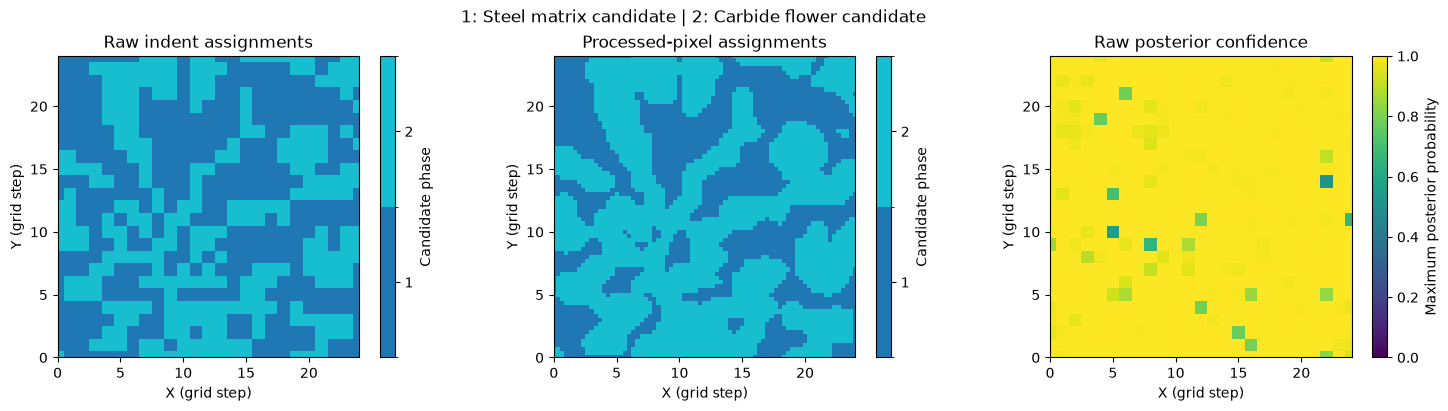

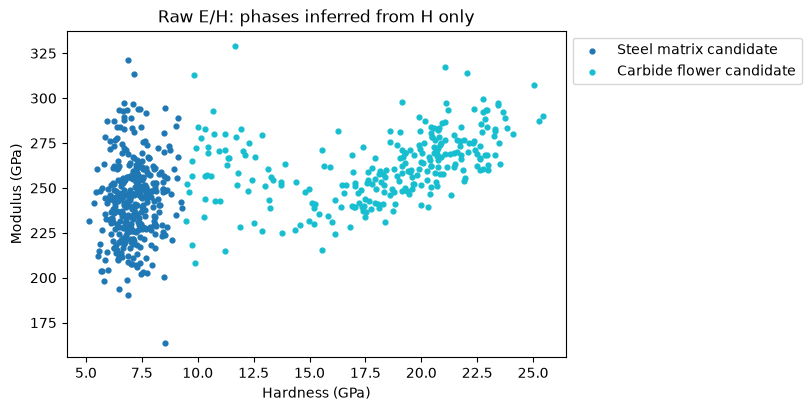

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
fig.suptitle(' | '.join(f'{index+1}: {name}' for index, name in enumerate(phase_names)))
for ax, labels, x, y, title in ((axes[0], labels_raw, x_raw, y_raw, 'Raw indent assignments'),
                              (axes[1], labels_processed, x_processed, y_processed, 'Processed-pixel assignments')):
    image = show_map(ax, np.ma.masked_equal(labels, 0), x, y, title, phase_cmap, phase_norm)
    ax.set_facecolor('lightgray')
    fig.colorbar(image, ax=ax, ticks=np.arange(1, N_PHASES+1), label='Candidate phase')
image = show_map(axes[2], confidence_raw, x_raw, y_raw, 'Raw posterior confidence', color_norm=plt.Normalize(0, 1))
fig.colorbar(image, ax=axes[2], label='Maximum posterior probability')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for phase in range(1, N_PHASES+1):
    selected = labels_raw == phase
    ax.scatter(H_raw[selected], E_raw[selected], s=12, color=phase_cmap(phase-1), label=phase_names[phase-1])
uncertain = valid_raw & (labels_raw == 0)
if uncertain.any():
    ax.scatter(H_raw[uncertain], E_raw[uncertain], s=12, color='gray', label='Uncertain')
ax.set(xlabel='Hardness (GPa)', ylabel='Modulus (GPa)', title=f'Raw E/H: phases inferred from {FIT_PROPERTY} only')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

## 6. Raw per-phase statistics and optional export

The table below always describes original paired measurements, even if you chose to fit processed pixels. SD is the sample standard deviation (`ddof=1`); NaN means fewer than two assigned measurements. Compare hard-assigned raw fractions with fitted mixture weights, which describe the selected analysis source. Processed phase maps are a visualization/pixel assignment, not an independent-indent count.

Optional export preserves every raw/processed coordinate, NaNs and phase 0, with a separate component-parameter table. Existing files are never overwritten. No export is written unless `EXPORT=True`.

In [10]:
phase_statistics = []
print('Phase   N_raw  Raw_fraction   E_mean   E_SD     H_mean   H_SD   Mixture_weight')
for index in range(N_PHASES):
    selected = labels_raw == index+1
    n = int(selected.sum())
    e_mean, h_mean = (float(E_raw[selected].mean()), float(H_raw[selected].mean())) if n else (np.nan, np.nan)
    e_sd, h_sd = (float(E_raw[selected].std(ddof=1)), float(H_raw[selected].std(ddof=1))) if n > 1 else (np.nan, np.nan)
    row = (index+1, n, n/np.count_nonzero(valid_raw), e_mean, e_sd, h_mean, h_sd, weights[index])
    phase_statistics.append(row)
    print(f'{index+1:5d} {n:7d} {row[2]:13.4f} {e_mean:8.3f} {e_sd:7.3f} {h_mean:9.3f} {h_sd:7.3f} {weights[index]:15.4f}')
    print(f'       {phase_names[index]}')
    if not n:
        print('  No raw measurements assigned to this component.')
phase_statistics = np.asarray(phase_statistics)
if ground_truth is not None:
    from sklearn.metrics import adjusted_rand_score
    assigned = valid_raw & (labels_raw > 0)
    if assigned.any():
        print('Synthetic adjusted Rand index:', adjusted_rand_score(ground_truth[assigned], labels_raw[assigned]))
    else:
        print('All synthetic assignments are uncertain; no recovery score is reported.')
else:
    print('Experimental components require independent physical-phase validation.')

if EXPORT:
    filenames = [EXPORT_DIR / name for name in ('phases_raw.csv', 'phases_processed.csv', 'components.csv', 'raw_phase_statistics.csv')]
    if any(filename.exists() for filename in filenames):
        raise FileExistsError('Choose a new EXPORT_DIR; existing analysis exports are not overwritten.')
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for filename, x, y, e, h, labels, confidence in (
        (filenames[0], x_raw, y_raw, E_raw, H_raw, labels_raw, confidence_raw),
        (filenames[1], x_processed, y_processed, E_processed, H_processed, labels_processed, confidence_processed)):
        xx, yy = np.meshgrid(x, y)
        table = np.column_stack([xx.ravel(), yy.ravel(), e.ravel(), h.ravel(), labels.ravel(), confidence.ravel()])
        np.savetxt(filename, table, delimiter=',', comments='', header=f'X_{COORDINATE_UNIT},Y_{COORDINATE_UNIT},E_GPa,H_GPa,Phase,Posterior_confidence')
    np.savetxt(filenames[2], np.column_stack([np.arange(1, N_PHASES+1), means, standard_deviations, weights]),
               delimiter=',', comments='', header=f'Phase,{FIT_PROPERTY}_mean_GPa,{FIT_PROPERTY}_SD_GPa,Mixture_weight_{ANALYSIS_SOURCE}')
    np.savetxt(filenames[3], phase_statistics, delimiter=',', comments='',
               header='Phase,N_raw,Raw_fraction,E_mean_GPa,E_SD_GPa,H_mean_GPa,H_SD_GPa,Mixture_weight')
    print('Exported:', EXPORT_DIR)
print({'source': DATA_SOURCE, 'analysis': ANALYSIS_SOURCE, 'property': FIT_PROPERTY,
       'phases': N_PHASES, 'refinement': REFINEMENT, 'sigma_refined_pixels': SMOOTH_SIGMA,
       'fill_missing': FILL_MISSING, 'minimum_posterior': MIN_POSTERIOR, 'seed': SEED,
       'phase_names': phase_names, 'serpentine_excel': SERPENTINE,
       'dx': DX, 'dy': DY, 'coordinate_unit': COORDINATE_UNIT})

Phase   N_raw  Raw_fraction   E_mean   E_SD     H_mean   H_SD   Mixture_weight
    1     355        0.5680  243.996  22.376     7.131   0.794          0.5660
       Steel matrix candidate
    2     270        0.4320  262.325  19.099    18.082   4.024          0.4340
       Carbide flower candidate
Experimental components require independent physical-phase validation.
{'source': 'excel', 'analysis': 'raw', 'property': 'H', 'phases': 2, 'refinement': 3, 'sigma_refined_pixels': 1.0, 'fill_missing': False, 'minimum_posterior': 0.0, 'seed': 42, 'phase_names': ['Steel matrix candidate', 'Carbide flower candidate'], 'serpentine_excel': True, 'dx': 1.0, 'dy': 1.0, 'coordinate_unit': 'grid step'}
